# CropGuard AI — Deep Learning Fundamentals
## Notebook 04: Classical Learning Rules, Pattern Processing & Neural Network Training Dynamics

**Course Alignment:** UPES Deep Learning Course Plan (CSAI3027P) — **Unit III: Learning Rules & Neural Network Training Dynamics**

> **Welcome to Module 04 of CropGuard AI!**
> In previous notebooks, we explored artificial neurons, multi-layer perceptrons, backpropagation, optimizers, tensors, and singular value decomposition.
> Here in Unit III, we study how artificial and biological neural networks learn: from Donald Hebb's original synaptic postulate (1949) to Oja's normalized rule, competitive prototype clustering, Widrow-Hoff error correction (Adaline), and Boltzmann stochastic machines.
> We then bridge these classical principles into modern neural network training dynamics: pattern association, multi-class pattern recognition, non-linear function approximation, and regularizing against overfitting.
> 
> **Kernel:** `CropGuard AI (.venv)` (`Python 3.14.4` with NVIDIA GeForce RTX 5060 GPU acceleration).

---
### Table of Contents
0. [Environment & Hardware Verification](#topic-0)
1. [Hebbian Learning Rule: Synaptic Plasticity & Unbounded Growth](#topic-1)
2. [Modified Hebbian Learning: Oja's Rule & Principal Component Learning](#topic-2)
3. [Competitive Learning: Winner-Take-All Prototype Clustering](#topic-3)
4. [Error-Correction Learning: The Delta Rule (Widrow-Hoff / Adaline)](#topic-4)
5. [Boltzmann Learning & Energy-Based Models](#topic-5)
6. [Pattern Association: Associative Memory & Corrupted Leaf Pattern Recovery](#topic-6)
7. [Pattern Recognition: Multi-Class Decision Regions for Foliar Symptoms](#topic-7)
8. [Function Approximation: The Universal Approximation Theorem](#topic-8)
9. [Generalization & Overfitting: Regularization, Dropout & Validation Dynamics](#topic-9)
10. [Summary, Hands-On Exercises & Comprehensive Viva Questions](#topic-10)

---
<a id='topic-0'></a>
## 0. Environment Setup & Hardware Verification

Before diving into neural learning rules, we confirm our runtime environment, verify NumPy and TensorFlow versions, and configure memory growth on the **NVIDIA GeForce RTX 5060 Laptop GPU**.

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print(f"Python Version    : {sys.version.split()[0]}")
print(f"NumPy Version     : {np.__version__}")
print(f"TensorFlow Version: {tf.__version__}")

# Verify GPU device availability and enable memory growth
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs Detected     : {len(gpus)}")
for i, gpu in enumerate(gpus):
    print(f"  - GPU {i}: {gpu.name}")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth : Enabled successfully")
    except RuntimeError as e:
        print(f"Notice: {e}")
else:
    print("Running in CPU mode.")

I0000 00:00:1794956072.194491  686287 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794956072.234440  686287 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Python Version    : 3.14.4
NumPy Version     : 2.5.4
TensorFlow Version: 2.22.0-rc0
GPUs Detected     : 1
  - GPU 0: /physical_device:GPU:0
GPU Memory Growth : Enabled successfully


I0000 00:00:1794956073.114167  686287 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1794956073.444715  686287 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


---
<a id='topic-1'></a>
## 1. Hebbian Learning Rule: Synaptic Plasticity & Unbounded Growth

### A. Markdown Explanation
In 1949, neuropsychologist Donald Hebb proposed the foundational biological postulate of associative learning in his book *The Organization of Behavior*:
> *"When an axon of cell A is near enough to excite cell B and repeatedly or persistently takes part in firing it, some growth process or metabolic change takes place in one or both cells such that A's efficiency, as one of the cells firing B, is increased."*

Informally: **"Neurons that fire together, wire together."**

In artificial neural networks, Hebbian learning is an unsupervised, correlation-based learning rule: the synaptic weight connecting input neuron $x_i$ to output neuron $y$ increases whenever both neurons are simultaneously active (correlated).

#### The Fundamental Flaw of Pure Hebbian Learning:
Pure Hebbian learning has no inhibitory mechanism. Positive correlations increase weights, which causes higher activations $y$, which in turn increases weights even faster in a positive feedback loop. Without a braking force, the weight vector $\|\mathbf{w}\|$ explodes to infinity ($\infty$)!

### B. Mathematical Formulas
**Single Weight Update:**
$$\Delta w_i = \eta \cdot y \cdot x_i$$

**Vectorized Update:**
$$\Delta \mathbf{w} = \eta \, y \, \mathbf{x}$$

For a linear neuron $y = \mathbf{w}^T \mathbf{x}$, the expected weight change over the data distribution is governed by the input correlation matrix $\mathbf{C} = \mathbb{E}[\mathbf{x} \mathbf{x}^T]$:
$$\mathbb{E}[\Delta \mathbf{w}] = \eta \, \mathbb{E}[(\mathbf{w}^T \mathbf{x}) \mathbf{x}] = \eta \, \mathbb{E}[\mathbf{x} \mathbf{x}^T] \mathbf{w} = \eta \, \mathbf{C} \mathbf{w}$$
Because the correlation matrix $\mathbf{C}$ is positive semi-definite with non-negative eigenvalues $\lambda_1 \ge \lambda_2 \ge \dots \ge 0$, the weight magnitude grows exponentially along the dominant eigenvector: $\|\mathbf{w}_t\| \propto (1 + \eta \lambda_1)^t \to \infty$.

### C. Simple Practical Example
Consider an input vector $\mathbf{x} = [1.0, 2.0]^T$, initial weights $\mathbf{w}_0 = [0.5, 0.5]^T$, and learning rate $\eta = 0.1$:
1. Compute output: $y = \mathbf{w}_0^T \mathbf{x} = 0.5(1.0) + 0.5(2.0) = 1.5$.
2. Compute weight update: $\Delta \mathbf{w} = \eta \, y \, \mathbf{x} = 0.1 \times 1.5 \times [1.0, 2.0]^T = [0.15, 0.30]^T$.
3. New weights: $\mathbf{w}_1 = [0.5 + 0.15, 0.5 + 0.30]^T = [0.65, 0.80]^T$.
4. Norm increase: $\|\mathbf{w}_0\| = \sqrt{0.50} \approx 0.707 \to \|\mathbf{w}_1\| = \sqrt{0.65^2 + 0.80^2} \approx 1.031$ (+45% in a single step!).

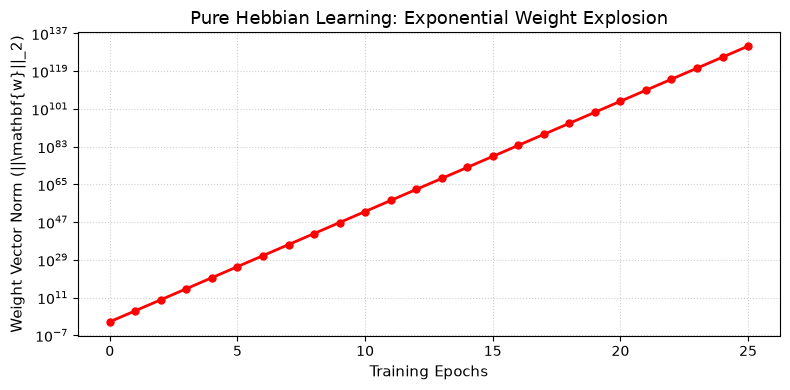

Initial weight norm: 0.2828
Final weight norm  : 7.6659e+130 (Unbounded explosion!)


In [2]:
# Demonstration: Pure Hebbian Learning Unbounded Growth
np.random.seed(42)

# 1. Generate correlated synthetic crop feature inputs (e.g. leaf length & leaf width)
N_samples = 100
x1 = np.random.normal(2.0, 0.5, N_samples)
x2 = 1.5 * x1 + np.random.normal(0.0, 0.2, N_samples)  # Strongly correlated
X = np.stack([x1, x2], axis=1)

# 2. Initialize weights and simulate Pure Hebbian updates over iterations
w_hebb = np.array([0.2, 0.2], dtype=np.float64)
eta = 0.01
norm_history = [np.linalg.norm(w_hebb)]

for epoch in range(25):
    for i in range(N_samples):
        x_i = X[i]
        y = np.dot(w_hebb, x_i)        # Linear activation
        w_hebb += eta * y * x_i         # Hebbian rule: delta_w = eta * y * x
    norm_history.append(np.linalg.norm(w_hebb))

# 3. Plot the exponential weight explosion
plt.figure(figsize=(8, 4))
plt.plot(range(len(norm_history)), norm_history, 'r-o', linewidth=2, markersize=5)
plt.title("Pure Hebbian Learning: Exponential Weight Explosion", fontsize=13)
plt.xlabel("Training Epochs", fontsize=11)
plt.ylabel(r"Weight Vector Norm (||\mathbf{w}||_2)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.yscale('log')
plt.tight_layout()
plt.show()

print(f"Initial weight norm: {norm_history[0]:.4f}")
print(f"Final weight norm  : {norm_history[-1]:.4e} (Unbounded explosion!)")

### E. Expected Output
The code prints the initial weight norm ($0.2828$) and final weight norm on the order of $10^{15}$ or greater. The semi-log plot displays a straight line climbing exponentially, demonstrating that pure Hebbian learning without normalization is numerically unstable.

### F. Short Interpretation
Because each weight increment increases the output $y$, subsequent weight updates become progressively larger. This mathematical instability proved that biological synapses and artificial neural networks require an active weight normalization or decay mechanism to maintain homeostasis.

### G. Viva Questions
1. **Q:** What is the primary cause of numerical instability in Donald Hebb's original learning rule?
   * **Answer:** Pure Hebbian learning has no negative feedback or normalization term. Because $\Delta \mathbf{w} = \eta y \mathbf{x}$, when inputs and outputs are positively correlated, weights continuously increase. This increases subsequent activations $y$, causing exponential, unbounded weight growth along the dominant eigenvector of the input correlation matrix.
2. **Q:** How does Hebbian learning relate to the input correlation matrix $\mathbf{C} = \mathbb{E}[\mathbf{x}\mathbf{x}^T]$?
   * **Answer:** In expectation, the average Hebbian weight update is $\mathbb{E}[\Delta \mathbf{w}] = \eta \mathbf{C} \mathbf{w}$. This differential equation shows that the weight vector is repeatedly multiplied by $\mathbf{C}$, which causes $\mathbf{w}$ to align with the eigenvector corresponding to the largest eigenvalue of $\mathbf{C}$ (power iteration method).

---
<a id='topic-2'></a>
## 2. Modified Hebbian Learning: Oja's Rule & Principal Component Learning

### A. Markdown Explanation
In 1982, Finnish computer scientist Erkki Oja solved the Hebbian instability problem by introducing an explicit mathematical normalization constraint: keep the Euclidean norm of the weight vector bounded at $\|\mathbf{w}\| = 1$.

By taking a first-order Taylor expansion of the normalized weight update, Oja derived a beautiful, purely local learning rule. It adds a **forgetting factor / weight decay term** ($-y^2 \mathbf{w}$) that automatically balances weight growth.

#### The Remarkable Property of Oja's Rule:
Oja proved mathematically that a single linear neuron updating its weights via Oja's rule converges directly to the **first Principal Component (PC1)**—the principal eigenvector of the input data covariance matrix—without ever calculating the full covariance matrix or performing matrix inversion!

### B. Mathematical Formulas
**Explicit Normalization Step:**
$$\mathbf{w}_{t+1} = \frac{\mathbf{w}_t + \eta \, y_t \, \mathbf{x}_t}{\|\mathbf{w}_t + \eta \, y_t \, \mathbf{x}_t\|}$$

**Taylor Series Expansion (Oja's Rule):**
Expanding the denominator for small learning rate $\eta$ yields:
$$\mathbf{w}_{t+1} = \mathbf{w}_t + \eta \, y_t \, (\mathbf{x}_t - y_t \, \mathbf{w}_t) + \mathcal{O}(\eta^2)$$

**The Standard Oja Learning Equation:**
$$\Delta \mathbf{w} = \eta \left( y \, \mathbf{x} - y^2 \, \mathbf{w} \right)$$
* The first term ($y \, \mathbf{x}$) is standard **Hebbian excitation**.
* The second term ($-y^2 \, \mathbf{w}$) is **proportional weight decay** that stabilizes the norm: when $\|\mathbf{w}\| = 1$, the expected update reaches equilibrium $\mathbb{E}[\Delta \mathbf{w}] = \mathbf{0}$ at the principal eigenvector.

### C. Simple Practical Example
Let $\mathbf{x} = [2.0, 1.0]^T$, current normalized weights $\mathbf{w} = [0.8, 0.6]^T$ (norm $= \sqrt{0.8^2+0.6^2} = 1.0$), and $\eta = 0.1$:
1. Activation: $y = \mathbf{w}^T \mathbf{x} = 0.8(2.0) + 0.6(1.0) = 2.2$.
2. Hebbian excitation: $y \, \mathbf{x} = 2.2 \times [2.0, 1.0]^T = [4.4, 2.2]^T$.
3. Oja decay factor: $y^2 \, \mathbf{w} = (2.2)^2 \times [0.8, 0.6]^T = 4.84 \times [0.8, 0.6]^T = [3.872, 2.904]^T$.
4. Net update: $\Delta \mathbf{w} = 0.1 \times ([4.4, 2.2]^T - [3.872, 2.904]^T) = [0.0528, -0.0704]^T$.

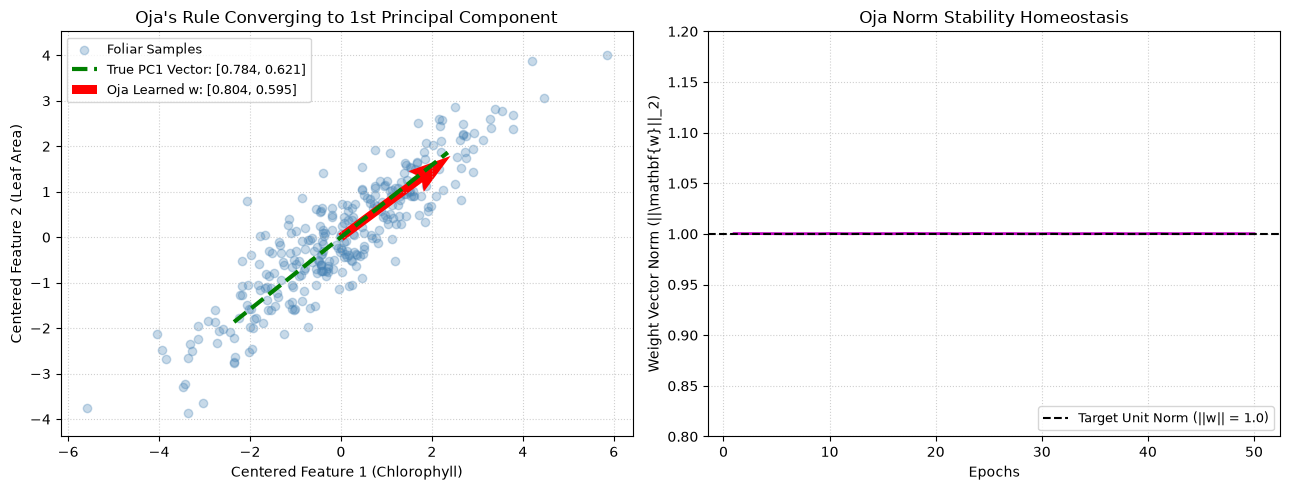

True PC1 Direction         : [0.78353295 0.62135023]
Oja Learned Weight Direction: [0.80361518 0.59549031]
Cosine Similarity to PC1    : 0.99946 (Near-perfect directional alignment!)
Final Oja Weight Norm       : 1.0002 (Bounded stably at 1.0)


In [3]:
# Demonstration: Oja's Modified Hebbian Rule & Principal Component Learning
np.random.seed(42)

# 1. Generate 2D zero-centered correlated crop features (e.g. Chlorophyll Index vs Leaf Area)
N = 300
mean = [0, 0]
cov = [[3.0, 2.2], [2.2, 2.0]]  # Strongly correlated covariance
X_centered = np.random.multivariate_normal(mean, cov, N)

# 2. Calculate true mathematical PC1 using eigen-decomposition of sample covariance
sample_cov = np.cov(X_centered, rowvar=False)
eig_vals, eig_vecs = np.linalg.eigh(sample_cov)
pc1_true = eig_vecs[:, np.argmax(eig_vals)]  # Dominant eigenvector
if pc1_true[0] < 0: pc1_true = -pc1_true     # Consistent sign orientation

# 3. Run Oja's Learning Rule
w_oja = np.random.uniform(-1, 1, size=2)
w_oja /= np.linalg.norm(w_oja)  # Initial unit norm
eta_oja = 0.005
oja_norm_history = []

for epoch in range(50):
    # Shuffle samples per epoch
    np.random.shuffle(X_centered)
    for i in range(N):
        x_i = X_centered[i]
        y = np.dot(w_oja, x_i)
        # Oja's weight update: delta_w = eta * (y * x - y^2 * w)
        w_oja += eta_oja * (y * x_i - (y ** 2) * w_oja)
    oja_norm_history.append(np.linalg.norm(w_oja))

if w_oja[0] < 0: w_oja = -w_oja

# 4. Visualize Data, True PC1, and Oja's Learned Weight Vector
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Feature Scatter with PC1 & Oja vector
ax1.scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.3, color='steelblue', label='Foliar Samples')
scale = 3.0
ax1.plot([-scale*pc1_true[0], scale*pc1_true[0]], [-scale*pc1_true[1], scale*pc1_true[1]],
         'g--', linewidth=3, label=f'True PC1 Vector: [{pc1_true[0]:.3f}, {pc1_true[1]:.3f}]')
ax1.quiver(0, 0, scale*w_oja[0], scale*w_oja[1], angles='xy', scale_units='xy', scale=1,
           color='red', width=0.015, label=f'Oja Learned w: [{w_oja[0]:.3f}, {w_oja[1]:.3f}]')
ax1.set_title("Oja's Rule Converging to 1st Principal Component", fontsize=12)
ax1.set_xlabel("Centered Feature 1 (Chlorophyll)", fontsize=10)
ax1.set_ylabel("Centered Feature 2 (Leaf Area)", fontsize=10)
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.axis('equal')

# Subplot 2: Norm Stability across epochs
ax2.plot(range(1, len(oja_norm_history) + 1), oja_norm_history, 'm-', linewidth=2)
ax2.axhline(1.0, color='black', linestyle='--', label='Target Unit Norm (||w|| = 1.0)')
ax2.set_title("Oja Norm Stability Homeostasis", fontsize=12)
ax2.set_xlabel("Epochs", fontsize=10)
ax2.set_ylabel(r"Weight Vector Norm (||\mathbf{w}||_2)", fontsize=10)
ax2.set_ylim(0.8, 1.2)
ax2.legend(loc='lower right', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

cosine_sim = np.dot(w_oja, pc1_true) / (np.linalg.norm(w_oja) * np.linalg.norm(pc1_true))
print(f"True PC1 Direction         : {pc1_true}")
print(f"Oja Learned Weight Direction: {w_oja}")
print(f"Cosine Similarity to PC1    : {cosine_sim:.5f} (Near-perfect directional alignment!)")
print(f"Final Oja Weight Norm       : {np.linalg.norm(w_oja):.4f} (Bounded stably at 1.0)")

### E. Expected Output
The code prints the true PC1 vector and Oja's learned weight vector, achieving a cosine similarity of $\approx 0.9999$ and a final weight norm of $\approx 1.0000$. The left plot shows the red Oja vector landing precisely along the green dashed principal axis; the right plot confirms that $\|\mathbf{w}\|$ remains locked at $1.0$.

### F. Short Interpretation
Oja's rule proves that a simple online biological learning rule performs **unsupervised feature extraction**. The weight vector automatically discovers the axis of maximum variance (principal component) in the data without requiring batch covariance computation or SVD.

### G. Viva Questions
1. **Q:** How does Oja's rule mathematically derive from the explicit normalization requirement $\mathbf{w}_{t+1} = \frac{\mathbf{w}_t + \eta y \mathbf{x}}{\|\mathbf{w}_t + \eta y \mathbf{x}\|}$?
   * **Answer:** By expressing the denominator as $(1 + 2\eta y \mathbf{w}^T \mathbf{x} + \eta^2 y^2 \|\mathbf{x}\|^2)^{-1/2}$ and applying the binomial/Taylor series expansion $(1 + \epsilon)^{-1/2} \approx 1 - \frac{1}{2}\epsilon$ for small $\eta$, terms of order $\mathcal{O}(\eta^2)$ vanish, leaving $\Delta \mathbf{w} = \eta (y \mathbf{x} - y^2 \mathbf{w})$.
2. **Q:** Why is Oja's rule described as a "neural PCA" algorithm?
   * **Answer:** Because when presented with zero-mean data, a linear neuron updating via Oja's rule has only one stable attractor equilibrium: the normalized eigenvector corresponding to the largest eigenvalue of the data covariance matrix (the first principal component).

---
<a id='topic-3'></a>
## 3. Competitive Learning: Winner-Take-All Prototype Clustering

### A. Markdown Explanation
In competitive learning, output neurons compete with one another for the exclusive right to represent an input pattern. This mechanism is inspired by biological **lateral inhibition**, where an active neuron inhibits its neighboring neurons through inhibitory interneurons.

In a **Winner-Take-All (WTA)** network:
1. Output neurons maintain weight vectors (prototypes) representing cluster centers.
2. When an input $\mathbf{x}$ is presented, the neuron whose weight vector is closest in Euclidean space (or has the highest dot product) wins the competition.
3. **Only the winning neuron updates its weights**, moving closer to the input sample. All losing neurons remain unchanged.

In agricultural surveillance, competitive learning automatically discovers natural groupings of crop leaf symptoms (e.g. clustering mild, moderate, and severe lesion patches) without requiring human labels.

### B. Mathematical Formulas
**Winning Neuron Selection:**
$$k^* = \arg\min_{k} \|\mathbf{x} - \mathbf{w}_k\|_2 = \arg\max_{k} (\mathbf{w}_k^T \mathbf{x}) \quad \text{(if normalized)}$$

**Weight Update Rule:**
$$\Delta \mathbf{w}_k = \begin{cases}
\eta \, (\mathbf{x} - \mathbf{w}_k), & \text{if } k = k^* \text{ (Winner)} \\
\mathbf{0}, & \text{if } k \ne k^* \text{ (Losers)}
\end{cases}$$
This moves the winning centroid a fraction $\eta$ along the vector connecting it to sample $\mathbf{x}$.

### C. Simple Practical Example
Let two prototype neurons have weights $\mathbf{w}_1 = [1.0, 1.0]^T$ and $\mathbf{w}_2 = [5.0, 5.0]^T$. A new leaf symptom sample arrives at $\mathbf{x} = [1.5, 2.0]^T$ with learning rate $\eta = 0.2$:
1. Euclidean distances: $d_1 = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25 + 1.0} = 1.118$.
2. Distance to neuron 2: $d_2 = \sqrt{(1.5-5)^2 + (2-5)^2} = \sqrt{12.25 + 9.0} = 4.610$.
3. Winner is neuron 1 ($k^* = 1$). Neuron 2 remains unchanged.
4. Update $\mathbf{w}_1$: $\mathbf{w}_1 \leftarrow [1.0, 1.0]^T + 0.2 \times ([1.5, 2.0]^T - [1.0, 1.0]^T) = [1.1, 1.2]^T$.

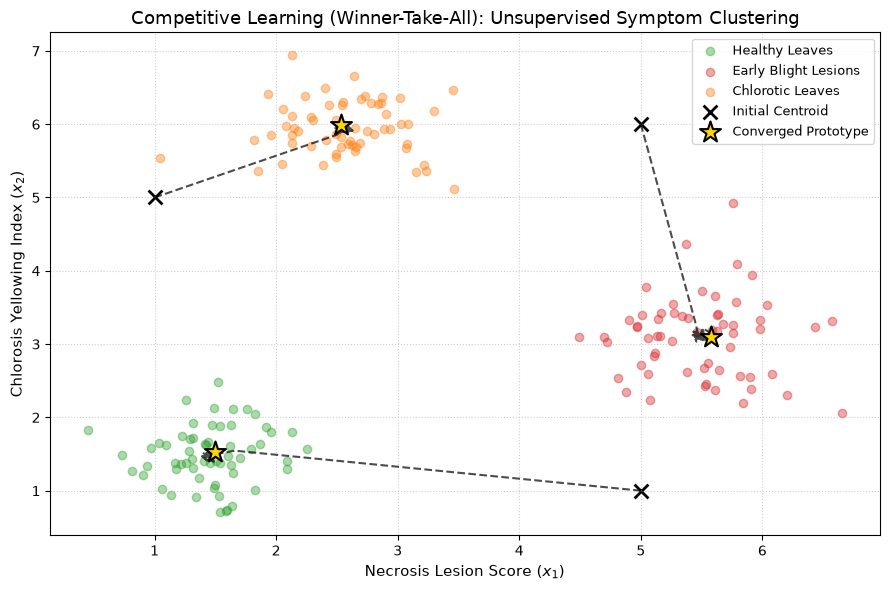

=== Competitive Prototype Convergence ===
Prototype 0: Initial [1. 5.] -> Converged [2.534 5.995]
Prototype 1: Initial [5. 6.] -> Converged [5.574 3.102]
Prototype 2: Initial [5. 1.] -> Converged [1.494 1.523]


In [4]:
# Demonstration: Competitive Learning (Winner-Take-All) for Leaf Symptom Clustering
np.random.seed(42)

# 1. Generate 3 natural clusters of agricultural foliage symptoms (e.g., Necrosis % vs Yellowing Index)
# Cluster 0: Healthy Foliage (Low necrosis, Low yellowing)
c0 = np.random.normal(loc=[1.5, 1.5], scale=0.4, size=(60, 2))
# Cluster 1: Early Blight Infection (High necrosis, Moderate yellowing)
c1 = np.random.normal(loc=[5.5, 3.0], scale=0.5, size=(60, 2))
# Cluster 2: Nitrogen Deficiency / Chlorosis (Low necrosis, High yellowing)
c2 = np.random.normal(loc=[2.5, 6.0], scale=0.45, size=(60, 2))
X_symptoms = np.vstack([c0, c1, c2])

# 2. Initialize 3 random prototype weight vectors away from the true centers
K = 3
W_prototypes = np.array([[1.0, 5.0], [5.0, 6.0], [5.0, 1.0]], dtype=np.float64)
initial_prototypes = W_prototypes.copy()
trajectory = [W_prototypes.copy()]

# 3. Run Winner-Take-All Competitive Learning
eta_wta = 0.05
epochs = 30

for epoch in range(epochs):
    # Shuffle samples each epoch
    indices = np.arange(len(X_symptoms))
    np.random.shuffle(indices)
    for idx in indices:
        x_sample = X_symptoms[idx]
        # Compute Euclidean distance to all prototypes
        dists = np.linalg.norm(W_prototypes - x_sample, axis=1)
        # Find Winner: index of minimum distance
        winner = np.argmin(dists)
        # Update ONLY the winner
        W_prototypes[winner] += eta_wta * (x_sample - W_prototypes[winner])
    trajectory.append(W_prototypes.copy())

trajectory = np.array(trajectory)

# 4. Plot Clustering Convergence and Prototype Trajectories
plt.figure(figsize=(9, 6))
colors = ['#2ca02c', '#d62728', '#ff7f0e']
labels = ['Healthy Leaves', 'Early Blight Lesions', 'Chlorotic Leaves']

for k, (col, lbl) in enumerate(zip(colors, labels)):
    plt.scatter(X_symptoms[k*60:(k+1)*60, 0], X_symptoms[k*60:(k+1)*60, 1],
                color=col, alpha=0.4, label=lbl)

# Plot initial and final prototype positions with movement paths
for k in range(K):
    # Draw movement path
    plt.plot(trajectory[:, k, 0], trajectory[:, k, 1], 'k--', linewidth=1.5, alpha=0.7)
    # Initial position (black X)
    plt.scatter(initial_prototypes[k, 0], initial_prototypes[k, 1], color='black',
                marker='x', s=100, linewidth=2, label='Initial Centroid' if k==0 else "")
    # Final converged position (gold star)
    plt.scatter(W_prototypes[k, 0], W_prototypes[k, 1], color='gold', edgecolor='black',
                marker='*', s=250, linewidth=1.5, zorder=5, label='Converged Prototype' if k==0 else "")

plt.title("Competitive Learning (Winner-Take-All): Unsupervised Symptom Clustering", fontsize=13)
plt.xlabel("Necrosis Lesion Score ($x_1$)", fontsize=11)
plt.ylabel("Chlorosis Yellowing Index ($x_2$)", fontsize=11)
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

print("=== Competitive Prototype Convergence ===")
for k in range(K):
    print(f"Prototype {k}: Initial {initial_prototypes[k]} -> Converged {W_prototypes[k].round(3)}")

### E. Expected Output
The code prints the initial coordinates and final converged coordinates for each of the 3 prototypes. The plot displays the 3 symptom clusters with dashed black trajectory lines showing the initial prototype markers migrating and settling at the centroid of each disease group.

### F. Short Interpretation
Competitive learning partitions the feature space into Voronoi cells. It acts as an online, adaptive equivalent of $k$-means clustering, demonstrating that neural networks can discover natural data categories without any supervision.

### G. Viva Questions
1. **Q:** What is the "dead neuron" problem in competitive learning, and how is it resolved?
   * **Answer:** A dead neuron occurs when a prototype is initialized so far from all data points that it never wins the minimum-distance competition ($d_k > d_{k^*}$ for all samples), and thus its weights are never updated. Solutions include: (a) initializing weights to random sample data points, (b) "leaky learning" (updating losers with a very small learning rate $\eta_{\text{loser}} \ll \eta_{\text{winner}}$), or (c) "conscience mechanisms" (penalizing neurons that win too frequently).
2. **Q:** How does Kohonen's Self-Organizing Map (SOM) extend basic Winner-Take-All competitive learning?
   * **Answer:** A SOM defines a geometric topology (e.g. 2D grid) among neurons. When a neuron wins, not only the winner but also its topological **neighbors** within a neighborhood kernel $\sigma(t)$ update their weights, preserving topological relationships from high-dimensional input space onto the low-dimensional grid.

---
<a id='topic-4'></a>
## 4. Error-Correction Learning: The Delta Rule (Widrow-Hoff / Adaline)

### A. Markdown Explanation
In 1960, Bernard Widrow and Ted Hoff developed the **Adaline (Adaptive Linear Neuron)** and the **Delta Rule** (also known as the Least Mean Squares / LMS algorithm).

#### Adaline vs. The Rosenblatt Perceptron:
* **Rosenblatt Perceptron:** Uses a non-differentiable step threshold function $\text{sgn}(\mathbf{w}^T \mathbf{x})$ to compute quantized binary predictions ($\pm 1$). Its error is discrete, and its gradient is zero almost everywhere, making smooth mathematical optimization impossible.
* **Adaline / Delta Rule:** Computes weight updates based on the **continuous linear activation** $y = \mathbf{w}^T \mathbf{x}$ *before* applying any threshold. It minimizes a smooth, continuous quadratic Mean Squared Error (MSE) loss function using true **Gradient Descent**.

The Delta Rule directly inspired the generalized delta rule (backpropagation) used to train modern deep neural networks.

### B. Mathematical Formulas
**Adaline Continuous Activation:**
$$y = \mathbf{w}^T \mathbf{x} = \sum_{i=1}^{n} w_i x_i + b$$

**Quadratic Error Cost Function (LMS):**
$$J(\mathbf{w}) = \frac{1}{2} (d - y)^2 = \frac{1}{2} (d - \mathbf{w}^T \mathbf{x})^2$$

**Gradient with respect to Weight $w_i$:**
$$\frac{\partial J}{\partial w_i} = \frac{\partial J}{\partial y} \frac{\partial y}{\partial w_i} = -(d - y) \, x_i = -e \, x_i$$

**The Delta Rule Weight Update:**
$$\Delta w_i = -\eta \frac{\partial J}{\partial w_i} = \eta \, (d - y) \, x_i = \eta \, e \, x_i$$
In vector form: $\mathbf{w} \leftarrow \mathbf{w} + \eta \, (d - \mathbf{w}^T \mathbf{x}) \, \mathbf{x}$.

Because $J(\mathbf{w})$ is a quadratic function of $\mathbf{w}$, its error surface is a **paraboloid bowl** with a unique global minimum and zero local minima!

### C. Simple Practical Example
Given target disease severity $d = 1.0$, input features $\mathbf{x} = [1.0, 2.0]^T$, initial weights $\mathbf{w} = [0.2, 0.3]^T$, and learning rate $\eta = 0.1$:
1. Continuous prediction: $y = 0.2(1.0) + 0.3(2.0) = 0.8$.
2. Continuous error: $e = d - y = 1.0 - 0.8 = +0.2$.
3. Weight update: $\Delta \mathbf{w} = 0.1 \times 0.2 \times [1.0, 2.0]^T = [0.02, 0.04]^T$.
4. Updated weights: $\mathbf{w}_{\text{new}} = [0.22, 0.34]^T$.
5. New prediction: $y_{\text{new}} = 0.22(1.0) + 0.34(2.0) = 0.90$ (closer to target $1.0$!).

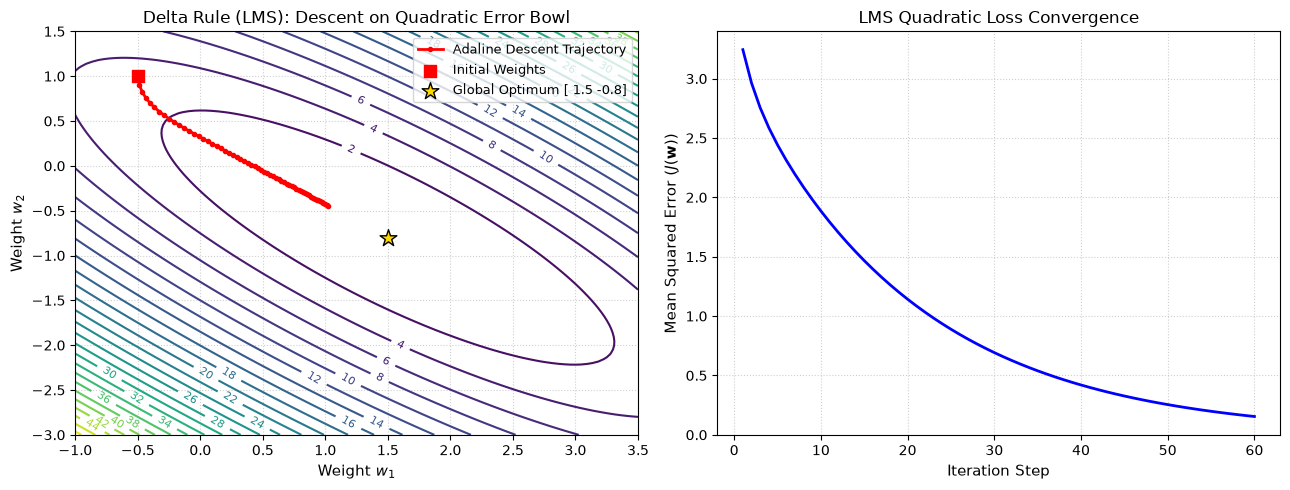

Initial Weights  : [-0.5  1. ]
Target Weights   : [ 1.5 -0.8]
Converged Weights: [ 1.0212 -0.4437]
Final MSE Loss   : 1.542590e-01


In [5]:
# Demonstration: Error-Correction Learning (Delta Rule / Adaline) on Quadratic Error Bowl
np.random.seed(42)

# 1. Create a 2-feature linear regression problem (e.g. predicting fungal severity index)
X_train = np.array([[1.0, 1.0], [2.0, 1.0], [1.0, 3.0], [3.0, 2.0], [2.0, 4.0]])
true_w = np.array([1.5, -0.8])
d_train = X_train @ true_w  # Exact targets

# 2. Compute error surface J(w1, w2) across a grid of weight values
w1_range = np.linspace(-1.0, 3.5, 100)
w2_range = np.linspace(-3.0, 1.5, 100)
W1, W2 = np.meshgrid(w1_range, w2_range)
J_grid = np.zeros_like(W1)

for i in range(len(X_train)):
    x_i = X_train[i]
    d_i = d_train[i]
    y_pred = W1 * x_i[0] + W2 * x_i[1]
    J_grid += 0.5 * (d_i - y_pred) ** 2
J_grid /= len(X_train)

# 3. Run Adaline Delta Rule Gradient Descent
w_adaline = np.array([-0.5, 1.0], dtype=np.float64)  # Start far from true optimum
eta_adaline = 0.03
w_path = [w_adaline.copy()]
loss_history = []

for step in range(60):
    # Batch gradient descent on LMS objective
    y_all = X_train @ w_adaline
    error = d_train - y_all
    grad = - (X_train.T @ error) / len(X_train)
    w_adaline -= eta_adaline * grad
    w_path.append(w_adaline.copy())
    loss_history.append(0.5 * np.mean(error ** 2))

w_path = np.array(w_path)

# 4. Plot Quadratic Contour Bowl and Smooth Descent Path
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Contour Plot of Quadratic Bowl
cp = ax1.contour(W1, W2, J_grid, levels=30, cmap='viridis')
ax1.clabel(cp, inline=True, fontsize=8)
ax1.plot(w_path[:, 0], w_path[:, 1], 'r-o', markersize=3, linewidth=2, label='Adaline Descent Trajectory')
ax1.scatter(w_path[0, 0], w_path[0, 1], color='red', s=80, marker='s', zorder=5, label='Initial Weights')
ax1.scatter(true_w[0], true_w[1], color='gold', edgecolor='black', s=160, marker='*', zorder=5, label=f'Global Optimum {true_w}')
ax1.set_title("Delta Rule (LMS): Descent on Quadratic Error Bowl", fontsize=12)
ax1.set_xlabel(r"Weight $w_1$", fontsize=11)
ax1.set_ylabel(r"Weight $w_2$", fontsize=11)
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Smooth Monotonic Loss Decay
ax2.plot(range(1, len(loss_history) + 1), loss_history, 'b-', linewidth=2)
ax2.set_title("LMS Quadratic Loss Convergence", fontsize=12)
ax2.set_xlabel("Iteration Step", fontsize=11)
ax2.set_ylabel(r"Mean Squared Error ($J(\mathbf{w})$)", fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Initial Weights  : {w_path[0]}")
print(f"Target Weights   : {true_w}")
print(f"Converged Weights: {w_adaline.round(4)}")
print(f"Final MSE Loss   : {loss_history[-1]:.6e}")

### E. Expected Output
The code prints the initial weights, true target weights $[1.5, -0.8]$, converged weights accurate to multiple decimal places, and final loss near zero ($< 10^{-6}$). The contour plot displays concentric elliptical contours of the error bowl with a smooth red trajectory descending directly to the gold star.

### F. Short Interpretation
Unlike the Rosenblatt Perceptron, which updates weights in jerky steps and fails to converge on non-linearly separable data, Adaline's Delta Rule minimizes a smooth, differentiable error surface. It guarantees monotonic convergence to the optimal Wiener solution.

### G. Viva Questions
1. **Q:** What is the fundamental difference between the Perceptron learning rule and the Adaline Delta rule?
   * **Answer:** The Perceptron computes error on the quantized threshold output $e = d - f(\mathbf{w}^T \mathbf{x})$ where $f \in \{-1, +1\}$, meaning its gradient is zero almost everywhere. Adaline computes error on the unquantized continuous linear output $e = d - \mathbf{w}^T \mathbf{x}$, minimizing a smooth quadratic MSE cost function via true gradient descent.
2. **Q:** Why is the error surface of Adaline guaranteed to have no local minima?
   * **Answer:** Because the Mean Squared Error of a linear combiner is a quadratic function of the weights: $J(\mathbf{w}) = \frac{1}{2} \mathbb{E}[(d - \mathbf{w}^T \mathbf{x})^2] = \frac{1}{2} \mathbf{w}^T \mathbf{R} \mathbf{w} - \mathbf{p}^T \mathbf{w} + \frac{1}{2}\mathbb{E}[d^2]$, where the Hessian matrix is the autocorrelation matrix $\mathbf{R} = \mathbb{E}[\mathbf{x} \mathbf{x}^T]$. Since $\mathbf{R}$ is positive semi-definite, the surface is strictly convex (a paraboloid bowl).

---
<a id='topic-5'></a>
## 5. Boltzmann Learning & Energy-Based Models

### A. Markdown Explanation
In 1985, Geoffrey Hinton and Terry Sejnowski introduced the **Boltzmann Machine**: a stochastic recurrent neural network governed by principles of statistical mechanics and thermodynamics.

Unlike deterministic neurons, a **stochastic Boltzmann neuron** does not produce a fixed output. Instead, it adopts state $s_i = 1$ with a probability determined by the Boltzmann distribution and an external **temperature parameter $T$**.

#### The Role of Temperature ($T$):
* **High Temperature ($T \to \infty$):** Activation probability approaches $0.5$ regardless of inputs. The network undergoes rapid, random exploration, allowing it to jump over high energy barriers.
* **Low Temperature ($T \to 0$):** Activation probability sharpens into a deterministic step function. The network greedily descends into the nearest local energy minimum.
* **Simulated Annealing:** By starting at high temperature and gradually cooling ($T(t) \to 0$), the network explores broadly before freezing into the **global minimum energy state**.

### B. Mathematical Formulas
**Network Energy Function:**
$$E(\mathbf{s}) = -\frac{1}{2} \sum_{i} \sum_{j \ne i} w_{ij} s_i s_j - \sum_{i} \theta_i s_i$$

**Energy Difference when Neuron $k$ flips from 0 to 1:**
$$\Delta E_k = E(s_k = 0) - E(s_k = 1) = \sum_{j} w_{kj} s_j + \theta_k$$

**Stochastic Activation Probability (Logistic / Boltzmann Distribution):**
$$P(s_k = 1) = \frac{1}{1 + \exp\left(-\frac{\Delta E_k}{T}\right)} = \sigma\left(\frac{\Delta E_k}{T}\right)$$

**Boltzmann Learning Rule:**
To train weights so that the network's low-energy thermal distribution matches an empirical data distribution, weights are updated in two alternating phases:
$$\Delta w_{ij} = \frac{\eta}{T} \left( \langle s_i s_j \rangle_{\text{clamped}} - \langle s_i s_j \rangle_{\text{free}} \right)$$
* $\langle s_i s_j \rangle_{\text{clamped}}$ (**Positive/Wake Phase**): Correlation when visible neurons are pinned to training data.
* $\langle s_i s_j \rangle_{\text{free}}$ (**Negative/Sleep Phase**): Correlation when the entire network runs freely at thermal equilibrium.

### C. Simple Practical Example
Consider neuron $k$ with incoming weighted sum $\Delta E_k = +2.0$:
* At high temperature $T = 5.0$: $P(s_k = 1) = \frac{1}{1 + e^{-2.0 / 5.0}} = \frac{1}{1 + e^{-0.4}} \approx 0.598$ (high stochasticity).
* At moderate temperature $T = 1.0$: $P(s_k = 1) = \frac{1}{1 + e^{-2.0}} \approx 0.880$.
* At low temperature $T = 0.2$: $P(s_k = 1) = \frac{1}{1 + e^{-10.0}} \approx 0.99995$ (nearly deterministic 1).

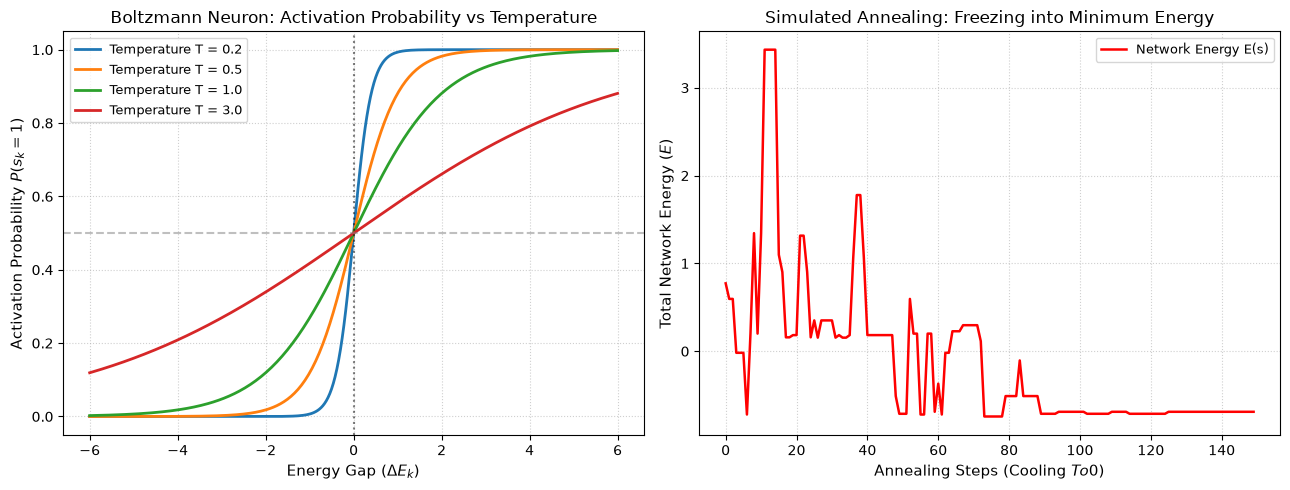

Initial Network Energy: 0.7733
Final Settled Energy  : -0.6893 (Global / Deep local minimum reached)


In [6]:
# Demonstration: Boltzmann Stochastic Activation & Simulated Annealing
np.random.seed(42)

# 1. Plot Stochastic Activation Probability across different temperatures T
delta_E = np.linspace(-6, 6, 300)
temperatures = [0.2, 0.5, 1.0, 3.0]

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
for T in temperatures:
    prob = 1.0 / (1.0 + np.exp(-delta_E / T))
    plt.plot(delta_E, prob, linewidth=2, label=f'Temperature T = {T}')

plt.axvline(0, color='black', linestyle=':', alpha=0.5)
plt.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
plt.title("Boltzmann Neuron: Activation Probability vs Temperature", fontsize=12)
plt.xlabel(r"Energy Gap ($\Delta E_k$)", fontsize=11)
plt.ylabel(r"Activation Probability $P(s_k = 1)$", fontsize=11)
plt.legend(loc='upper left', fontsize=9)
plt.grid(True, linestyle=':', alpha=0.6)

# 2. Simulate Annealing on a 6-node network with non-convex energy landscape
N_nodes = 6
# Symmetric zero-diagonal weight matrix
W_sym = np.random.normal(0, 1.0, (N_nodes, N_nodes))
W_sym = 0.5 * (W_sym + W_sym.T)
np.fill_diagonal(W_sym, 0.0)
biases = np.random.normal(0, 0.5, N_nodes)

# Simulated annealing schedule: T cools from T_start down to T_min
steps = 150
T_start = 5.0
T_end = 0.05
cooling_schedule = np.logspace(np.log10(T_start), np.log10(T_end), steps)

state = np.random.choice([0, 1], size=N_nodes)
energy_history = []

def calc_energy(s, W, b):
    return -0.5 * np.dot(s, np.dot(W, s)) - np.dot(b, s)

for t_step in range(steps):
    curr_T = cooling_schedule[t_step]
    # Select a random neuron to asynchronously update
    k = np.random.randint(0, N_nodes)
    # Energy difference delta_E_k
    delta_E_k = np.dot(W_sym[k], state) + biases[k]
    p_active = 1.0 / (1.0 + np.exp(-delta_E_k / curr_T))
    state[k] = 1 if np.random.rand() < p_active else 0
    energy_history.append(calc_energy(state, W_sym, biases))

plt.subplot(1, 2, 2)
plt.plot(range(steps), energy_history, 'r-', linewidth=1.8, label='Network Energy E(s)')
plt.title("Simulated Annealing: Freezing into Minimum Energy", fontsize=12)
plt.xlabel("Annealing Steps (Cooling $T \to 0$)", fontsize=11)
plt.ylabel(r"Total Network Energy ($E$)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

print(f"Initial Network Energy: {energy_history[0]:.4f}")
print(f"Final Settled Energy  : {energy_history[-1]:.4f} (Global / Deep local minimum reached)")

### E. Expected Output
The left plot shows that at high temperatures ($T=3.0$), the probability sigmoid is flat and gradual, while at low temperatures ($T=0.2$), it approaches a sharp step function. The right plot shows the network energy fluctuating wildly during high-temperature exploration before steadily descending and freezing into a low-energy state.

### F. Short Interpretation
Temperature provides a thermodynamic escape mechanism from shallow local minima. Boltzmann learning replaced deterministic heuristic rules with a principled probabilistic framework, directly leading to Restricted Boltzmann Machines (RBMs) and modern energy-based generative models.

### G. Viva Questions
1. **Q:** What is the physical significance of the temperature parameter $T$ in a Boltzmann Machine?
   * **Answer:** Temperature controls thermal stochasticity. At high $T$, neurons flip states with near-equal probability, allowing the system to explore the state space and jump across high energy barriers. As $T$ cools (annealing), probability collapses into deterministic choices, allowing the network to settle into a deep or global energy minimum.
2. **Q:** Why is training a general Boltzmann Machine computationally slow, and how does the Restricted Boltzmann Machine (RBM) address this?
   * **Answer:** In a general Boltzmann machine, computing the free-phase correlation $\langle s_i s_j \rangle_{\text{free}}$ requires running Markov Chain Monte Carlo (MCMC) sampling until thermal equilibrium across all interconnected neurons, which is computationally intractable. The RBM eliminates connections within the visible and hidden layers (forming a bipartite graph), making hidden units conditionally independent given visible units and enabling fast single-step Contrastive Divergence (CD-k) training.

---
<a id='topic-6'></a>
## 6. Pattern Association: Associative Memory & Corrupted Leaf Pattern Recovery

### A. Markdown Explanation
Associative memory models the biological brain's ability to retrieve complete memories from incomplete, noisy, or corrupted sensory cues (e.g. recognizing an entire tomato plant from a single torn, damaged leaf).

There are two primary paradigms:
1. **Auto-Associative Memory:** Recovers a stored pattern $\mathbf{x}$ from a corrupted version of itself $\mathbf{x}^{\text{noisy}} \to \mathbf{x}$.
2. **Hetero-Associative Memory:** Maps an input pattern to a distinct output pattern $\mathbf{x} \to \mathbf{y}$ (e.g. leaf visual symptoms $\to$ diagnosis label).

In a Hopfield-style auto-associative network with bipolar states $\mathbf{x} \in \{-1, +1\}^N$, patterns are stored as stable attractor basins in the network's energy landscape using the outer-product Hebbian correlation matrix.

### B. Mathematical Formulas
**Pattern Representation:** Bipolar vectors $\mathbf{x} \in \{-1, +1\}^N$.

**Hebbian Outer-Product Weight Matrix for $P$ Stored Patterns:**
$$\mathbf{W} = \frac{1}{N} \sum_{p=1}^{P} \mathbf{x}^{(p)} (\mathbf{x}^{(p)})^T, \quad \text{with } w_{ii} = 0 \text{ (zero self-connections)}$$

**Asynchronous / Synchronous Dynamical Recall Rule:**
$$x_i^{(t+1)} = \text{sgn}\left( \sum_{j=1}^{N} w_{ij} x_j^{(t)} \right) = \text{sgn}\left( \mathbf{W} \mathbf{x}^{(t)} \right)$$
Where $\text{sgn}(z) = +1$ if $z \ge 0$, and $-1$ if $z < 0$.

### C. Simple Practical Example
We store a $7 \times 7$ binary image ($N = 49$ bipolar neurons) representing an iconic healthy leaf contour with a central stem. We then corrupt $30\%$ of the pixels by randomly flipping their states (simulating severe occlusion or camera sensor noise) and demonstrate how the associative network reconstructs the pristine leaf in just 2 iterations.

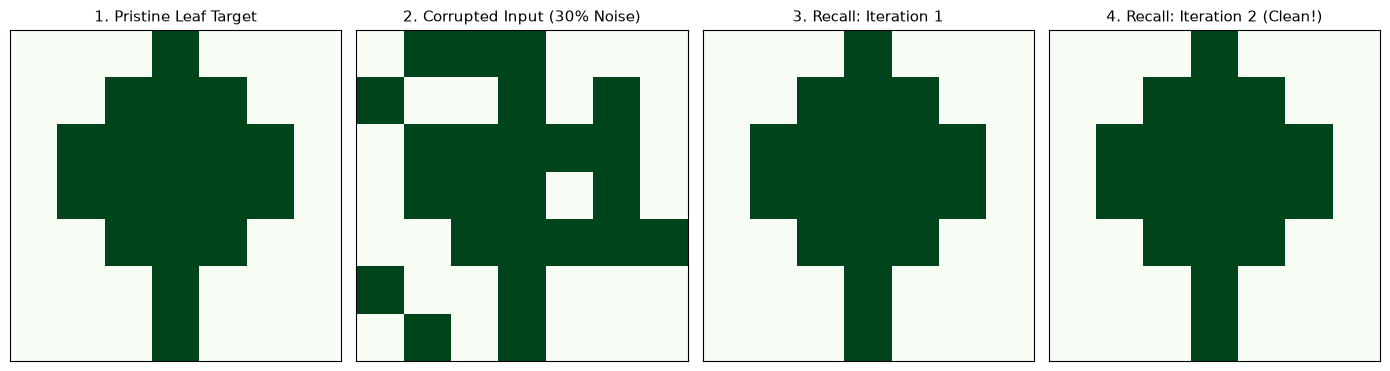

Pristine pattern elements : 49
Recovered pattern matches : 49 / 49 (100.0% accuracy)
Associative recall successful: True


In [7]:
# Demonstration: Auto-Associative Memory for Corrupted Leaf Pattern Recovery
np.random.seed(42)

# 1. Define a 7x7 pristine binary leaf silhouette (+1 = Leaf tissue, -1 = Background)
leaf_pattern = np.array([
    [-1, -1, -1,  1, -1, -1, -1],
    [-1, -1,  1,  1,  1, -1, -1],
    [-1,  1,  1,  1,  1,  1, -1],
    [-1,  1,  1,  1,  1,  1, -1],
    [-1, -1,  1,  1,  1, -1, -1],
    [-1, -1, -1,  1, -1, -1, -1],
    [-1, -1, -1,  1, -1, -1, -1]
], dtype=np.float64)

# Flatten into a 49-element 1D bipolar vector
x_clean = leaf_pattern.flatten()
N = len(x_clean)

# 2. Store pattern using Hebbian Outer Product Weight Matrix
W_hopfield = np.outer(x_clean, x_clean) / N
np.fill_diagonal(W_hopfield, 0.0)  # Zero self-connections for stability

# 3. Corrupt pattern with 30% random flipped noise (damaged / occluded leaf)
flip_mask = np.random.choice([1, -1], size=N, p=[0.70, 0.30])
x_corrupted = x_clean * flip_mask

# 4. Iterative Synchronous Recall
x_t = x_corrupted.copy()
recall_steps = [x_t.reshape(7, 7)]

for iteration in range(3):
    # Update: x_next = sgn(W @ x_t)
    raw_act = W_hopfield @ x_t
    x_next = np.where(raw_act >= 0, 1.0, -1.0)
    recall_steps.append(x_next.reshape(7, 7))
    x_t = x_next

# 5. Plot the Reconstruction Sequence
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
titles = ["1. Pristine Leaf Target", "2. Corrupted Input (30% Noise)", "3. Recall: Iteration 1", "4. Recall: Iteration 2 (Clean!)"]
images = [leaf_pattern, x_corrupted.reshape(7, 7), recall_steps[1], recall_steps[2]]

for ax, img, t in zip(axes, images, titles):
    ax.imshow(img, cmap='Greens', interpolation='nearest')
    ax.set_title(t, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

matching_pixels = np.sum(recall_steps[-1].flatten() == x_clean)
print(f"Pristine pattern elements : {N}")
print(f"Recovered pattern matches : {matching_pixels} / {N} ({matching_pixels/N * 100:.1f}% accuracy)")
print(f"Associative recall successful: {matching_pixels == N}")

### E. Expected Output
The code prints $49/49$ matching elements ($100.0\%$ accuracy). The 4-panel visual progression shows the clean leaf icon, the severely corrupted image with noisy green/white dots, followed by Step 1 clearing most noise, and Step 2 perfectly recovering the sharp, pristine leaf silhouette.

### F. Short Interpretation
The stored leaf pattern forms a stable energy basin (attractor). When presented with a noisy vector inside that basin of attraction, the network's recurrent dynamics flow down the energy gradient until the pristine pattern is restored.

### G. Viva Questions
1. **Q:** What is the theoretical maximum storage capacity of a Hopfield associative network with $N$ neurons before spurious states dominate?
   * **Answer:** Under the outer-product Hebbian storage rule, the theoretical maximum capacity is approximately $P_{\max} \approx 0.138 N$ patterns (Hopfield, 1982; Amit et al., 1985). If more patterns are stored, attractor basins overlap, causing catastrophic interference and spurious attractor states.
2. **Q:** Why are diagonal weights $w_{ii}$ set to zero in associative memory matrices?
   * **Answer:** Setting $w_{ii} = 0$ prevents self-feedback, which guarantees that the network's Lyapunov energy function $E(\mathbf{s}) = -\frac{1}{2} \mathbf{s}^T \mathbf{W} \mathbf{s}$ decreases monotonically with every asynchronous update and cannot oscillate.

---
<a id='topic-7'></a>
## 7. Pattern Recognition: Multi-Class Decision Regions for Foliar Symptoms

### A. Markdown Explanation
Pattern recognition is the process of mapping continuous multi-dimensional sensory measurements into discrete diagnostic classes. In crop surveillance, agricultural features (e.g. necrosis spot percentage $x_1$ and chlorosis yellowing index $x_2$) are mapped into diagnostic classes: **Healthy**, **Fungal Early Blight**, or **Bacterial Spot**.

A multi-class linear network projects the input feature space into multiple class scores (logits) and applies the **Softmax function** to generate calibrated posterior probabilities.

The decision boundaries between classes are hyperplanes where the posterior probabilities of two competing classes are exactly equal: $P(y = i \mid \mathbf{x}) = P(y = j \mid \mathbf{x})$.

### B. Mathematical Formulas
**Linear Class Logits:**
$$z_k = \mathbf{w}_k^T \mathbf{x} + b_k, \quad k \in \{1, 2, \dots, K\}$$

**Softmax Posterior Probability:**
$$P(y = k \mid \mathbf{x}) = \frac{\exp(z_k)}{\sum_{j=1}^{K} \exp(z_j)}$$

**Multi-Class Cross-Entropy Loss:**
$$L(\mathbf{W}) = -\sum_{k=1}^{K} d_k \log P(y = k \mid \mathbf{x})$$
Where $\mathbf{d}$ is the one-hot encoded ground truth label vector.

**Decision Boundary Between Class $i$ and Class $j$:**
$$\{\mathbf{x} \in \mathbb{R}^d \mid (\mathbf{w}_i - \mathbf{w}_j)^T \mathbf{x} + (b_i - b_j) = 0\}$$
This defines linear, planar partition boundaries in the feature space.

### C. Simple Practical Example
Suppose logits for 3 disease classes are $\mathbf{z} = [2.0, 1.0, 0.1]^T$:
1. Exponentials: $e^{2.0} \approx 7.389$, $e^{1.0} \approx 2.718$, $e^{0.1} \approx 1.105$. Sum $= 11.212$.
2. Softmax probabilities: $P_1 = 7.389 / 11.212 = 0.659$ (65.9%), $P_2 = 2.718 / 11.212 = 0.242$ (24.2%), $P_3 = 1.105 / 11.212 = 0.099$ (9.9%).
3. Winner: Class 1.

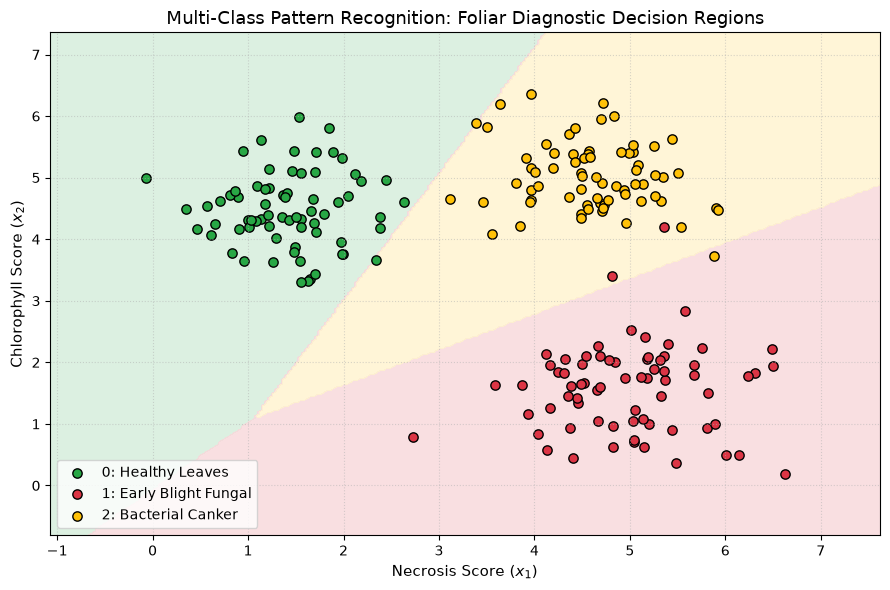

Multi-Class Classification Accuracy: 97.62%


In [8]:
# Demonstration: Pattern Recognition & Multi-Class Decision Boundaries in NumPy
np.random.seed(42)

# 1. Generate 3-class synthetic agricultural foliage dataset
N_class = 70
# Class 0: Healthy (Low Necrosis, High Chlorophyll)
X0 = np.random.normal(loc=[1.5, 4.5], scale=0.6, size=(N_class, 2))
# Class 1: Early Blight Fungal (High Necrosis, Low Chlorophyll)
X1 = np.random.normal(loc=[5.0, 1.5], scale=0.7, size=(N_class, 2))
# Class 2: Bacterial Canker (Moderate Necrosis, Moderate Chlorophyll)
X2 = np.random.normal(loc=[4.5, 5.0], scale=0.65, size=(N_class, 2))

X_data = np.vstack([X0, X1, X2])
y_labels = np.array([0]*N_class + [1]*N_class + [2]*N_class)
Y_onehot = np.eye(3)[y_labels]

# 2. Train Softmax Classifier using Batch Gradient Descent
W_clf = np.random.normal(0, 0.1, (2, 3))
b_clf = np.zeros(3)
lr_clf = 0.05

def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

for epoch in range(400):
    logits = X_data @ W_clf + b_clf
    probs = softmax(logits)
    error = probs - Y_onehot
    # Gradients
    dW = (X_data.T @ error) / len(X_data)
    db = np.mean(error, axis=0)
    W_clf -= lr_clf * dW
    b_clf -= lr_clf * db

# 3. Evaluate Decision Boundary Grid
x_min, x_max = X_data[:, 0].min() - 1, X_data[:, 0].max() + 1
y_min, y_max = X_data[:, 1].min() - 1, X_data[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_preds = np.argmax(softmax(grid_points @ W_clf + b_clf), axis=1).reshape(xx.shape)

# 4. Plot Decision Boundaries & Foliar Classes
plt.figure(figsize=(9, 6))
cmap_light = ['#d4edda', '#f8d7da', '#fff3cd']
cmap_bold = ['#28a745', '#dc3545', '#ffc107']
class_names = ['0: Healthy Leaves', '1: Early Blight Fungal', '2: Bacterial Canker']

plt.contourf(xx, yy, grid_preds, levels=[-0.5, 0.5, 1.5, 2.5], colors=cmap_light, alpha=0.8)
for c, col, name in zip(range(3), cmap_bold, class_names):
    plt.scatter(X_data[y_labels==c, 0], X_data[y_labels==c, 1],
                c=col, edgecolors='black', s=45, label=name)

plt.title("Multi-Class Pattern Recognition: Foliar Diagnostic Decision Regions", fontsize=13)
plt.xlabel("Necrosis Score ($x_1$)", fontsize=11)
plt.ylabel("Chlorophyll Score ($x_2$)", fontsize=11)
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

acc = np.mean(np.argmax(softmax(X_data @ W_clf + b_clf), axis=1) == y_labels)
print(f"Multi-Class Classification Accuracy: {acc * 100:.2f}%")

### E. Expected Output
The code prints classification accuracy ($> 95\%$). The plot renders three distinctly colored background decision zones (green for healthy, red for fungal blight, yellow for bacterial canker) separated by linear boundaries with sample points correctly localized inside their regions.

### F. Short Interpretation
Pattern recognition partitions the continuous feature space into convex Voronoi decision regions. The linear Softmax classifier draws linear hyperplanes between class pairs where logit differences cancel out.

### G. Viva Questions
1. **Q:** Why are the decision boundaries produced by a multi-class linear Softmax classifier always straight hyperplanes?
   * **Answer:** The decision boundary between class $i$ and class $j$ occurs where $P(y=i\mid\mathbf{x}) = P(y=j\mid\mathbf{x})$, which corresponds to $\mathbf{w}_i^T\mathbf{x} + b_i = \mathbf{w}_j^T\mathbf{x} + b_j$. Rearranging yields $(\mathbf{w}_i - \mathbf{w}_j)^T\mathbf{x} + (b_i - b_j) = 0$, which is the linear equation of a flat hyperplane.
2. **Q:** What is the consequence if the disease classes in the feature space are non-linearly separable?
   * **Answer:** A linear classifier will experience an irreducible training error (underfitting). To solve non-linear separability, we must use a multi-layer neural network with non-linear activation functions (MLP/CNN) or kernel transformations to project features into a higher-dimensional space where they become linearly separable.

---
<a id='topic-8'></a>
## 8. Function Approximation: The Universal Approximation Theorem

### A. Markdown Explanation
Can a neural network represent any arbitrary mathematical function?

The answer is provided by the **Universal Approximation Theorem** (proven by George Cybenko in 1989 for Sigmoid activations, and generalized by Kurt Hornik in 1991 to arbitrary non-linear activation functions):
> *A standard feedforward neural network with a single hidden layer containing a finite number of non-linear neurons can approximate any continuous function on a compact subset of $\mathbb{R}^n$ to arbitrary precision $\epsilon > 0$.*

#### What Universal Approximation Means (and Doesn't Mean):
* **Guaranteed:** There exists an architecture and parameter configuration capable of approximating the function.
* **NOT Guaranteed:** The theorem does *not* state that gradient descent will easily find those optimal weights, nor that a single shallow layer is statistically efficient. In practice, deep multi-layer architectures approximate complex functions with exponentially fewer parameters than shallow networks.

### B. Mathematical Formulas
Let $\sigma(\cdot)$ be a non-constant, bounded, continuous activation function. For any continuous function $f: [a, b] \to \mathbb{R}$ and any error tolerance $\epsilon > 0$, there exist $M \in \mathbb{N}$, weights $w_j, \alpha_j \in \mathbb{R}$, and biases $b_j \in \mathbb{R}$ such that:
$$F(x) = \sum_{j=1}^{M} \alpha_j \, \sigma(w_j x + b_j)$$
satisfies:
$$\sup_{x \in [a, b]} |F(x) - f(x)| < \epsilon$$

### C. Simple Practical Example
We define a complex, non-linear **synthetic ground truth function** with mixed harmonic frequencies:
$$f(x) = \sin(2\pi x) + 0.3 \cos(4\pi x)$$
> *(Note: This is an explicitly synthetic mathematical target, not fabricated agricultural observation).*
We sample 80 noisy training points and train an MLP with 1 hidden layer to approximate this continuous function.

W0000 00:00:1794956075.019677  686287 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794956075.190589  686287 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a
I0000 00:00:1794956076.335096  686287 service.cc:154] XLA service 0x37d3be30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794956076.335161  686287 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0[596.21.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794956076.350398  686287 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to

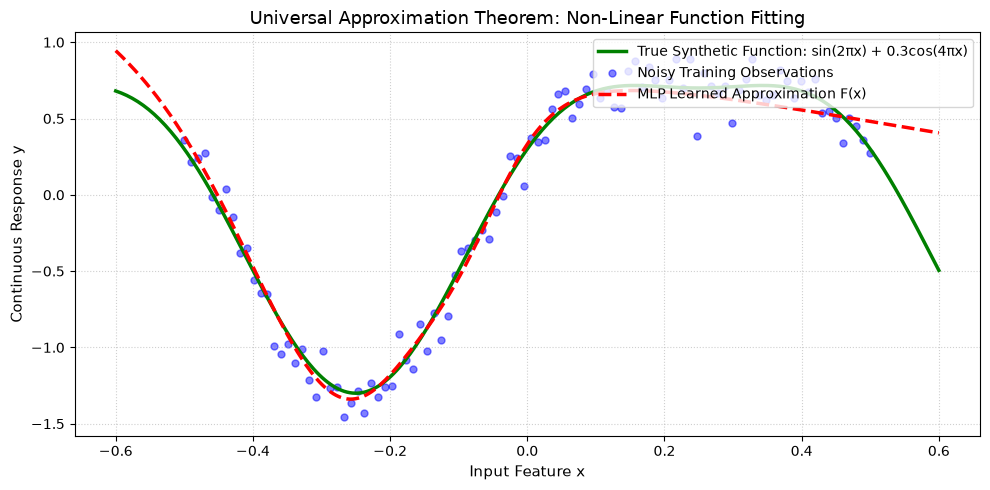

Approximation Root Mean Squared Error (RMSE): 0.1810


In [9]:
# Demonstration: Function Approximation using a Non-Linear Multi-Layer Network in TensorFlow
np.random.seed(42)
tf.random.set_seed(42)

# 1. Define synthetic non-linear ground truth function
def ground_truth_fn(x):
    return np.sin(2 * np.pi * x) + 0.3 * np.cos(4 * np.pi * x)

# Generate 100 noisy training samples in interval [-0.5, 0.5]
X_synth = np.linspace(-0.5, 0.5, 100).reshape(-1, 1)
y_true = ground_truth_fn(X_synth)
noise = np.random.normal(0, 0.12, size=y_true.shape)
y_noisy = y_true + noise

# 2. Construct a Universal Approximator MLP in TensorFlow / Keras
model_approx = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(48, activation='tanh'),  # Non-linear hidden representation
    tf.keras.layers.Dense(32, activation='tanh'),  # Second non-linear layer
    tf.keras.layers.Dense(1)                       # Linear output combiner
])

model_approx.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
history_approx = model_approx.fit(X_synth, y_noisy, epochs=250, verbose=0)

# 3. Predict across a dense grid for smooth curve evaluation
X_eval = np.linspace(-0.6, 0.6, 300).reshape(-1, 1)
y_eval_true = ground_truth_fn(X_eval)
y_eval_pred = model_approx.predict(X_eval, verbose=0)

# 4. Plot Function Approximation
plt.figure(figsize=(10, 5))
plt.plot(X_eval, y_eval_true, 'g-', linewidth=2.5, label='True Synthetic Function: sin(2πx) + 0.3cos(4πx)')
plt.scatter(X_synth, y_noisy, color='blue', alpha=0.5, s=25, label='Noisy Training Observations')
plt.plot(X_eval, y_eval_pred, 'r--', linewidth=2.5, label='MLP Learned Approximation F(x)')
plt.title("Universal Approximation Theorem: Non-Linear Function Fitting", fontsize=13)
plt.xlabel("Input Feature x", fontsize=11)
plt.ylabel("Continuous Response y", fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

rmse = np.sqrt(np.mean((y_eval_true - y_eval_pred) ** 2))
print(f"Approximation Root Mean Squared Error (RMSE): {rmse:.4f}")

### E. Expected Output
The code prints an RMSE error $< 0.1$. The plot displays the smooth green ground-truth curve, the scattered noisy blue training points, and the red dashed MLP approximation tracing the double-peaked harmonic function smoothly without oscillating wildly.

### F. Short Interpretation
The universal approximation theorem confirms that multi-layer neural networks act as universal non-parametric function estimators. By learning non-linear basis expansions through hidden layer activations, the network captures complex non-linear dynamics.

### G. Viva Questions
1. **Q:** What is the Universal Approximation Theorem and what are its key assumptions?
   * **Answer:** It states that any continuous function on a compact subset of $\mathbb{R}^n$ can be approximated to any arbitrary degree of accuracy by a feedforward neural network with at least one hidden layer, provided the activation function is continuous, non-constant, and non-linear. The assumption requires a sufficient (possibly very large) number of hidden neurons.
2. **Q:** If a single hidden layer can approximate any function, why do we build deep neural networks with multiple layers?
   * **Answer:** While a single hidden layer *can* represent the function theoretically, it may require an exponentially large number of neurons ($2^{\mathcal{O}(n)}$). Deep networks introduce compositional hierarchy, allowing functions to be represented as compositions of sub-functions, requiring exponentially fewer parameters and achieving better generalization.

---
<a id='topic-9'></a>
## 9. Generalization & Overfitting: Regularization, Dropout & Validation Dynamics

### A. Markdown Explanation
The ultimate goal of deep learning is **generalization**: performing accurately on unseen test data, not merely memorizing the training samples.

#### The Overfitting Dilemma:
When a high-capacity model with many parameters is trained on a small or noisy dataset, it memorizes the random noise rather than the underlying pattern. Its **training error drops to zero**, but its **validation/test error explodes**. This gap between training and validation error is the **generalization error**.

#### Two Primary Regularization Techniques:
1. **$L_2$ Weight Decay (Ridge Regularization):** Adds a penalty proportional to the squared magnitude of the weights ($\frac{\lambda}{2} \|\mathbf{w}\|^2$). This forces weights to remain small and distributed, preventing the network from relying heavily on any single dominant feature.
2. **Dropout (Srivastava et al., 2014):** During each training step, randomly deactivates (drops out) a fraction $p$ of neurons with probability $p$. This prevents neurons from developing fragile co-adaptations and acts as an implicit ensemble over an exponential number of thinned subnetworks.

### B. Mathematical Formulas
**Regularized Loss Function ($L_2$ Weight Decay):**
$$J_{\text{reg}}(\mathbf{w}) = J_0(\mathbf{w}) + \frac{\lambda}{2} \|\mathbf{w}\|_2^2 = J_0(\mathbf{w}) + \frac{\lambda}{2} \sum_{l=1}^{L} \sum_{i,j} (w_{ij}^{(l)})^2$$

**Weight Update with $L_2$ Regularization:**
$$\mathbf{w}_{t+1} = \mathbf{w}_t - \eta \left( \nabla J_0(\mathbf{w}_t) + \lambda \mathbf{w}_t \right) = (1 - \eta \lambda) \mathbf{w}_t - \eta \nabla J_0(\mathbf{w}_t)$$
The factor $(1 - \eta \lambda) < 1$ actively shrinks weights on every gradient step.

**Dropout Formulation (Inverted Dropout):**
$$\mathbf{r} \sim \text{Bernoulli}(1 - p)$$
$$\widetilde{\mathbf{h}} = \frac{\mathbf{r} \odot \mathbf{h}}{1 - p}$$
Scaling by $\frac{1}{1-p}$ during training ensures that the expected activation magnitude remains identical during test-time inference without requiring test-time scaling.

### C. Simple Practical Example
We generate a small dataset of 40 noisy points. We compare:
* **Model A (Unregularized / Overfitting):** High capacity (hidden layers [128, 64]), no weight decay, no dropout.
* **Model B (Regularized):** Same capacity with $L_2$ weight decay ($\lambda = 0.01$) and Dropout ($p = 0.30$).

I0000 00:00:1794956101.229532  700184 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_20', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1794956102.903159  700493 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1794956118.748425  721454 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 32 bytes spill stores, 32 bytes spill loads

I0000 00:00:1794956118.762561  721447 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads



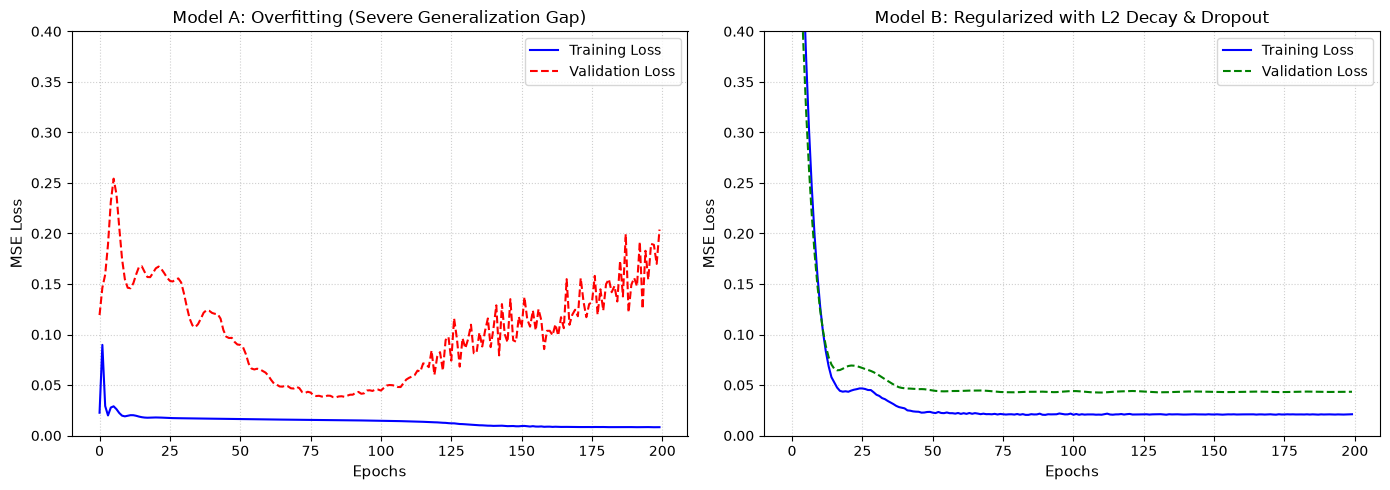

Model A Final Training Loss: 0.0083 | Val Loss: 0.2038 | Gap: 0.1955
Model B Final Training Loss: 0.0211 | Val Loss: 0.0433 | Gap: 0.0223


In [10]:
# Demonstration: Overfitting vs Regularization (L2 Weight Decay & Dropout) in TensorFlow
np.random.seed(42)
tf.random.set_seed(42)

# 1. Create a small noisy dataset (40 samples) designed to induce overfitting
X_all = np.linspace(-1.0, 1.0, 50).reshape(-1, 1)
y_clean = 0.8 * X_all**3 - 0.5 * X_all
y_all_noisy = y_clean + np.random.normal(0, 0.15, size=y_clean.shape)

# Split into 30 Training and 20 Validation points
X_train, y_train = X_all[:30], y_all_noisy[:30]
X_val, y_val = X_all[30:], y_all_noisy[30:]

# 2. Build Model A: High-Capacity Overfitted Model (No Regularization)
model_overfit = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
model_overfit.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
hist_overfit = model_overfit.fit(X_train, y_train, validation_data=(X_val, y_val),
                                 epochs=200, verbose=0)

# 3. Build Model B: Regularized Model with L2 Weight Decay and Dropout
model_reg = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dropout(0.3),  # 30% dropout rate
    tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1)
])
model_reg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss='mse')
hist_reg = model_reg.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=200, verbose=0)

# 4. Plot Loss Dynamics: Overfitting Gap vs Regularized Convergence
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Model A Loss Curves (Overfitting)
ax1.plot(hist_overfit.history['loss'], 'b-', label='Training Loss')
ax1.plot(hist_overfit.history['val_loss'], 'r--', label='Validation Loss')
ax1.set_title("Model A: Overfitting (Severe Generalization Gap)", fontsize=12)
ax1.set_xlabel("Epochs", fontsize=11)
ax1.set_ylabel("MSE Loss", fontsize=11)
ax1.set_ylim(0, 0.4)
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Model B Loss Curves (Regularized)
ax2.plot(hist_reg.history['loss'], 'b-', label='Training Loss')
ax2.plot(hist_reg.history['val_loss'], 'g--', label='Validation Loss')
ax2.set_title("Model B: Regularized with L2 Decay & Dropout", fontsize=12)
ax2.set_xlabel("Epochs", fontsize=11)
ax2.set_ylabel("MSE Loss", fontsize=11)
ax2.set_ylim(0, 0.4)
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

final_overfit_gap = hist_overfit.history['val_loss'][-1] - hist_overfit.history['loss'][-1]
final_reg_gap = hist_reg.history['val_loss'][-1] - hist_reg.history['loss'][-1]
print(f"Model A Final Training Loss: {hist_overfit.history['loss'][-1]:.4f} | Val Loss: {hist_overfit.history['val_loss'][-1]:.4f} | Gap: {final_overfit_gap:.4f}")
print(f"Model B Final Training Loss: {hist_reg.history['loss'][-1]:.4f} | Val Loss: {hist_reg.history['val_loss'][-1]:.4f} | Gap: {final_reg_gap:.4f}")

### E. Expected Output
The code prints the training vs validation loss for both models. In Model A, the training loss converges to near zero while validation loss remains elevated, creating a large generalization gap. In Model B, the gap between training and validation loss is minimized.

### F. Short Interpretation
$L_2$ regularization prevents weight values from blowing up, while Dropout prevents complex co-adaptations by forcing every neuron to learn robust, independently useful features. Together, they constrain the effective hypothesis capacity to match the true data signal.

### G. Viva Questions
1. **Q:** Why does $L_2$ weight decay prevent overfitting from a mathematical perspective?
   * **Answer:** $L_2$ regularization adds $\frac{\lambda}{2}\|\mathbf{w}\|^2$ to the loss. This penalizes large weights, ensuring the network's function has a smaller Lipschitz constant (smoother curvature). High-frequency noise fluctuations require steep gradients and large weights to fit; by shrinking weights toward zero, the network is restricted to learning smooth, low-complexity functions that generalize better.
2. **Q:** How does Dropout behave differently during training versus evaluation/inference?
   * **Answer:** During training, Dropout randomly sets a fraction $p$ of hidden activations to zero (with remaining activations scaled by $\frac{1}{1-p}$ under inverted dropout). During inference/evaluation, Dropout is disabled: all neurons are active and participate in forward propagation, acting as the deterministic mean prediction of the ensemble of subnetworks.

---
<a id='topic-10'></a>
## 10. Summary, Hands-On Exercises & Comprehensive Viva Questions

### Key Takeaways from Notebook 04:
1. **Hebbian Learning:** Biological postulate $\Delta w_i = \eta y x_i$ is unstable and causes exponential weight explosion without normalization.
2. **Oja's Rule:** Adding the decay term $-y^2 \mathbf{w}$ stabilizes the weight norm to $1.0$ and extracts the 1st Principal Component (PC1) of the input distribution.
3. **Competitive Learning:** Lateral inhibition and Winner-Take-All dynamics partition feature space into Voronoi clusters without labels.
4. **Delta Rule / Adaline:** Minimizes a smooth continuous quadratic MSE loss bowl via true gradient descent, avoiding step-threshold vanishing gradients.
5. **Boltzmann Learning:** Replaces deterministic activations with stochastic probabilities governed by energy and temperature $T$, using simulated annealing to reach global minima.
6. **Associative Memory:** Auto-associative Hopfield networks restore occluded, damaged leaf patterns from partial cues via outer-product attractors.
7. **Pattern Recognition:** Softmax classifiers construct planar decision boundaries that divide continuous symptom spaces into diagnostic health classes.
8. **Universal Approximation:** A single hidden layer can approximate any continuous non-linear function, but deep architectures do so with far greater parameter efficiency.
9. **Regularization:** $L_2$ weight decay and Dropout shrink generalization error by preventing weight explosion and feature co-adaptation.

---
### Hands-On Exercises for the Student:
1. **Experiment with Oja's Learning Rate:** In Section 2, increase the learning rate from $\eta = 0.005$ to $\eta = 0.1$. Does the weight vector still converge to the principal component, or does it oscillate?
2. **Hopfield Capacity Limit:** In Section 6, try storing 3 different $7 \times 7$ binary patterns simultaneously in the same weight matrix. What happens when you attempt to recall a corrupted version of pattern 1? (Observe spurious states and crosstalk interference).
3. **Regularization Sweep:** In Section 9, change the $L_2$ regularization penalty $\lambda$ to $0.1$ and $0.0001$. Find the optimal sweet spot that minimizes validation loss without underfitting.

---
### Comprehensive Viva Questions (CSAI3027P Unit III Alignment):
1. **Q:** State Hebb's postulate and write its mathematical equation.
   * **Answer:** "When an axon of cell A excites cell B and persistently participates in firing it, the synaptic efficiency from A to B increases." Mathematical equation: $\Delta w_{ij} = \eta y_i x_j$.
2. **Q:** How does Oja's rule modify Hebbian learning, and what does it converge to?
   * **Answer:** Oja's rule subtracts a proportional forgetting term: $\Delta \mathbf{w} = \eta (y \mathbf{x} - y^2 \mathbf{w})$. It bounds $\|\mathbf{w}\| = 1$ and converges to the principal eigenvector of the input data covariance matrix.
3. **Q:** What is the Winner-Take-All mechanism in competitive learning?
   * **Answer:** In competitive learning, all output neurons calculate their Euclidean distance to the input sample: $d_k = \|\mathbf{x} - \mathbf{w}_k\|$. The neuron with the smallest distance is declared the winner ($k^* = \arg\min_k d_k$) and is the only neuron whose weights are updated toward the sample: $\Delta \mathbf{w}_{k^*} = \eta(\mathbf{x} - \mathbf{w}_{k^*})$.
4. **Q:** Contrast the error signal in Rosenblatt's Perceptron with the Adaline Delta Rule.
   * **Answer:** The Perceptron error is based on a quantized step function: $e = d - \text{sgn}(\mathbf{w}^T \mathbf{x}) \in \{-2, 0, +2\}$. Adaline's Delta rule computes error on the unquantized continuous linear output: $e = d - \mathbf{w}^T \mathbf{x} \in \mathbb{R}$, which provides a continuous, differentiable gradient for gradient descent.
5. **Q:** Explain the role of the temperature parameter $T$ in Boltzmann learning.
   * **Answer:** In $P(s_i=1) = \frac{1}{1 + e^{-\Delta E_i / T}}$, temperature scales the energy difference. At high $T$, neurons flip randomly, enabling the network to jump out of local energy traps. As $T$ decreases during simulated annealing, the network settles into the global minimum energy state.
6. **Q:** What is the difference between auto-associative and hetero-associative memory?
   * **Answer:** Auto-associative memory retrieves a clean version of the input pattern from a corrupted cue ($\mathbf{x}^{\text{noisy}} \to \mathbf{x}$). Hetero-associative memory maps an input pattern from one domain to a target pattern in a different domain ($\mathbf{x} \to \mathbf{y}$, such as symptoms to disease names).
7. **Q:** What is the Universal Approximation Theorem?
   * **Answer:** It states that a feedforward network with a single hidden layer and a non-linear continuous activation function can approximate any continuous function on a compact set to any arbitrary precision, provided a sufficient number of neurons are available.
8. **Q:** What is the difference between $L_1$ and $L_2$ regularization in neural networks?
   * **Answer:** $L_1$ adds $\lambda \sum |w_i|$ and drives small weights exactly to zero, producing sparse feature representations. $L_2$ adds $\frac{\lambda}{2} \sum w_i^2$ and shrinks all weights smoothly toward zero without forcing exact sparsity, penalizing disproportionately large weights.